# 🩺 Medical Cost Prediction
### Machine Learning | Linear Regression

> Can we predict medical insurance charges using basic health information such as age, BMI, and smoking status? In this project, we analyze the data, train a Linear Regression model, and compare its predictions with actual charges.

**Dataset:** `insurance.csv` · **1,338 rows, 7 columns**  
**Problem:** Regression · **Target:** `charges` (billed medical expenses)  
**Source:** [Medical Cost Personal Datasets on Kaggle](https://www.kaggle.com/datasets/mirichoi0218/insurance)


## Data Dictionary

| Column | Meaning | Short explanation |
|---|---|---|
| `age` | Age | Age of policyholder |
| `sex` | Sex | Male or female in this dataset |
| `bmi` | Body Mass Index | Weight relative to height squared |
| `children` | Dependents | Number of children/dependents |
| `smoker` | Smoking status | Yes or no |
| `region` | Region | US geographic region |
| `charges` | Billed medical charges | Numeric target to predict |

## 1. Import and Load Data

> We read the CSV file with Pandas and inspect the first five rows

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. Explore the Data (EDA)

> We check the dataset structure, missing values, and numerical summaries

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [3]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [4]:
df.describe().round(2)

,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


## 3. Data Visualization

> We compare charges by smoking status and look for a relationship with age

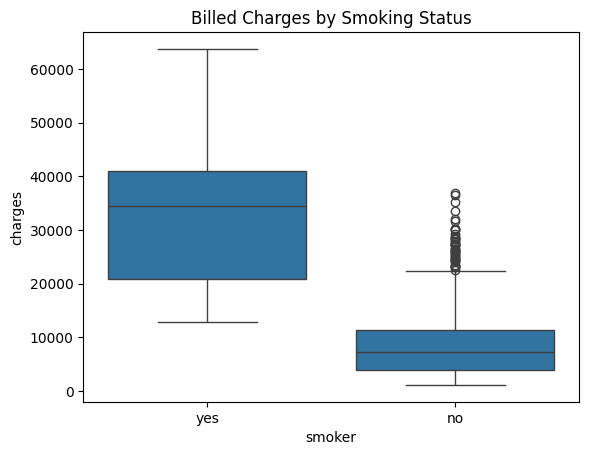

In [5]:
sns.boxplot(data=df, x='smoker', y='charges')
plt.title('Billed Charges by Smoking Status')
plt.show()

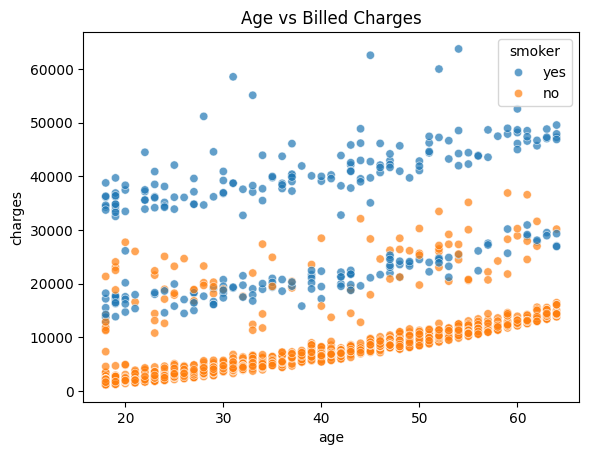

In [6]:
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', alpha=0.7)
plt.title('Age vs Billed Charges')
plt.show()

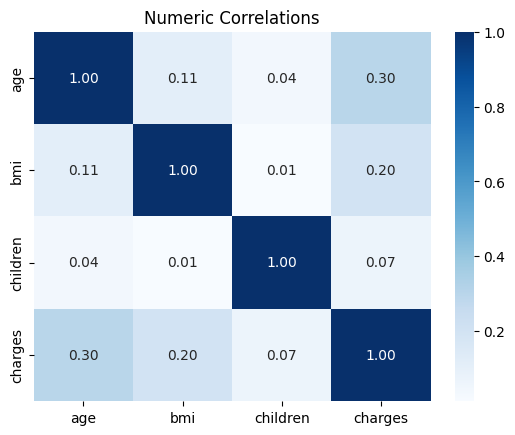

In [7]:
sns.heatmap(df[['age','bmi','children','charges']].corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Numeric Correlations')
plt.show()

## 4. Features and Target

> `X` contains the input data and `y` contains the charges. We convert the categorical columns into numeric columns

In [8]:
X = pd.get_dummies(df.drop('charges', axis=1), drop_first=True)
y = df['charges']
X.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,False,True,False,False,True
1,18,33.770,1,True,False,False,True,False
2,28,33.000,3,True,False,False,True,False
3,33,22.705,0,True,False,True,False,False
4,32,28.880,0,True,False,True,False,False


## 5. Train and Test

> We train on 80% of the data and keep 20% to test new predictions

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

## 6. Train Linear Regression

> The model learns how the features relate to billed costs, then predicts values on the test set

In [10]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## 7. Model Evaluation

> MAE and RMSE measure prediction error in cost units. R² describes how much variation the model explains

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('MAE:', round(mean_absolute_error(y_test, y_pred), 2))
print('RMSE:', round(mean_squared_error(y_test, y_pred) ** 0.5, 2))
print('R²:', round(r2_score(y_test, y_pred), 3))

MAE: 4181.19
RMSE: 5796.28
R²: 0.784


## 8. Actual vs Predicted

> We plot predicted costs against real values to see where the model makes larger errors

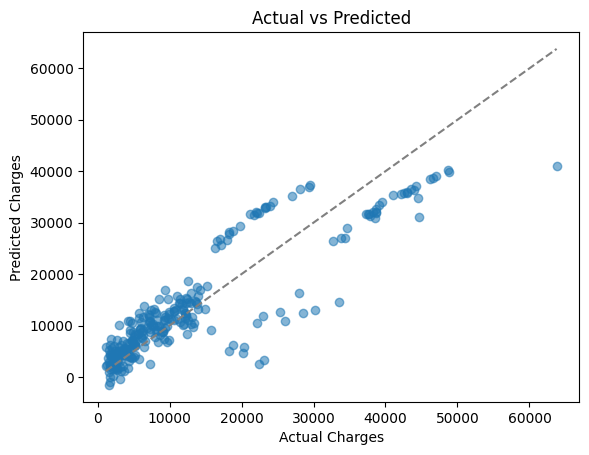

In [12]:
plt.scatter(y_test, y_pred, alpha=0.55)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--', color='gray')
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted')
plt.show()

In [13]:
pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred}).head(10).round(2)

,Actual,Predicted
0,9095.07,8969.55
1,5272.18,7068.75
2,29330.98,36858.41
3,9301.89,9454.68
4,33750.29,26973.17
5,4536.26,10864.11
6,2117.34,170.28
7,14210.54,16903.45
8,3732.63,1092.43
9,10264.44,11218.34


## 9. Conclusion

**Test results (80/20 split):** MAE **4181.19**, RMSE **5796.28**, R² **0.784**.


> Linear Regression provides a simple first estimate of billed charges. The test metrics and actual-vs-predicted chart show the remaining errors.

**Limitations:** This is a small historical example from US insurance data. The relationships are not causal and predictions are not medical or insurance advice. A single split does not prove general performance.